# Cross-Sectional ML for Long-Short Equity Selection
## Post-modelling validation: strategy, equity curves, significance tests, SHAP

Runs on the artefacts Part 2 wrote (`pred_test.csv`, `pred_train_oof.csv`,
`pred_test_all.csv`, `model_meta.json`) plus `market.csv` and
`model_train.csv` / `model_test.csv`.

In [1]:
import ast
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

warnings.filterwarnings("ignore")
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

DATA = "data"
meta = json.load(open(f"{DATA}/model_meta.json"))
fmeta = json.load(open(f"{DATA}/feature_meta.json"))
FEATURES = fmeta["selected"]

te = pd.read_csv(f"{DATA}/pred_test.csv", parse_dates=["date"])
tr = pd.read_csv(f"{DATA}/pred_train_oof.csv", parse_dates=["date"])
allm = pd.read_csv(f"{DATA}/pred_test_all.csv", parse_dates=["date"])
mkt = pd.read_csv(f"{DATA}/market.csv", parse_dates=["date"])[["date", "mktrf", "rf"]]

# pred_train_oof did not carry stock_spread, but model_train.csv does -- merge
# it in so the train curve is costed the same way as the test curve.
tr = tr.merge(pd.read_csv(f"{DATA}/model_train.csv", parse_dates=["date"])
              [["date", "ticker", "stock_spread"]],
              on=["date", "ticker"], how="left")

WINNER = meta["winner"]
print(f"Winner from Part 2: {WINNER}")
print(f"  validation rank IC {meta['validation']['RankIC']:+.4f} (t {meta['validation']['RankIC_t']:+.2f})")
print(f"  test       rank IC {meta['test']['RankIC']:+.4f} (t {meta['test']['RankIC_t']:+.2f})")

# Frozen-upstream assertions
assert te.groupby("date")["ticker"].nunique().eq(20).all(), "unbalanced test cross-section"
assert tr.groupby("date")["ticker"].nunique().eq(20).all(), "unbalanced train cross-section"
n_models = allm["model"].nunique()
assert n_models * len(te) == len(allm), "pred_test_all is not models x test rows"
assert WINNER in set(allm["model"]), "winner missing from pred_test_all"
print(f"\n[ok] test {te['date'].nunique()} days x 20 names | "
      f"train OOF {tr['date'].nunique()} days | {n_models} models' test predictions loaded")

Winner from Part 2: KerasMLP
  validation rank IC +0.0300 (t +2.51)
  test       rank IC -0.0028 (t -0.17)

[ok] test 248 days x 20 names | train OOF 550 days | 8 models' test predictions loaded


## 1. The trading strategy

Each day, rank the 20 names by predicted relative return; go **long the top
quintile (4 names) and short the bottom quintile (4 names)**, equal-weighted,
dollar-neutral, rebalanced daily.

*Book normalisation.* Capital is 1.0 and each of the 8 open positions is sized
1/8, so every daily P&L is already **normalised by the number of open
positions** — the guideline's requirement for multi-target models. Position
P&L is taken from the demeaned target, which is *identical* to using the raw
forward return here: the demeaning constant is the same for both legs of a
dollar-neutral book and cancels exactly.

*Costs.* Charged on **turnover**, not on holding: each unit of weight change
pays half that name's **quoted spread** (`stock_spread`, the CRSP bid/ask
relative spread carried through from Part 1) per side. Two flat sensitivities
(5 and 10 bps round trip) are reported alongside.

In [2]:
N_POS = 8      # 4 long + 4 short; profits are normalised by this (open positions)
FLAT_BPS = {"5bpsRT": 2.5e-4, "10bpsRT": 5.0e-4}   # per side; RT = round trip


def backtest(df):
    """Equal-weight quintile long-short, daily rebalance.

    Weights: +1/8 on the 4 highest-prediction names, -1/8 on the 4 lowest, so
    the book sums to zero with unit gross. Daily P&L is sum(w * target); using
    the demeaned target equals using fwd_logret because the demeaning constant
    cancels between the long and short legs.
    """
    rows, prev_w = [], None
    for _, g in df.groupby("date"):
        g = g.sort_values("pred", kind="mergesort")            # stable ordering
        k = len(g) // 5
        w = pd.Series(0.0, index=g.index)
        w.iloc[:k] = -1.0 / N_POS                              # bottom quintile -> short
        w.iloc[len(g) - k:] = 1.0 / N_POS                      # top quintile -> long
        gross = float((w * g["target"]).sum())

        spread = (g["stock_spread"].fillna(g["stock_spread"].median())
                  .fillna(0.0).to_numpy())
        dw = w.abs().to_numpy() if prev_w is None else \
            (w - prev_w.reindex(w.index).fillna(0.0)).abs().to_numpy()
        turnover = dw.sum() / 2.0                              # one-way fraction traded
        cost_spread = float(np.sum(dw * spread / 2.0))         # half spread per side
        rows.append({
            "date": g["date"].iloc[0], "gross": gross,
            "net_spread": gross - cost_spread,
            **{f"net_{name}": gross - float(dw.sum()) * half
               for name, half in FLAT_BPS.items()},
            "turnover": turnover, "cost_spread": cost_spread,
        })
        prev_w = w
    return pd.DataFrame(rows).set_index("date")


strat_te = backtest(te)
strat_tr = backtest(tr)
ew_te = te.groupby("date")["fwd_logret"].mean()                # 20-name buy & hold

print("TEST strategy, first 3 days:")
print(strat_te.head(3).round(6).to_string())
print(f"\nmean daily gross       {strat_te['gross'].mean():+.6f}")
print(f"mean daily net(spread) {strat_te['net_spread'].mean():+.6f}")
print(f"mean one-way turnover  {strat_te['turnover'].mean():.1%} | "
      f"mean spread cost {strat_te['cost_spread'].mean():.6f}")

TEST strategy, first 3 days:
               gross  net_spread  net_5bpsRT  net_10bpsRT  turnover  cost_spread
date                                                                            
2024-09-03  0.003014    0.002560    0.002764     0.002514       0.5     0.000454
2024-09-04  0.004479    0.004018    0.004229     0.003979       0.5     0.000461
2024-09-05 -0.007402   -0.007784   -0.007652    -0.007902       0.5     0.000382

mean daily gross       -0.000208
mean daily net(spread) -0.000717
mean one-way turnover  50.0% | mean spread cost 0.000509


In [3]:
# Mean next-day relative return by PREDICTED quintile (alpha-lens style).
# t-stats are day-level, per the Part 2 doctrine: per-day quintile means first,
# then a t across days -- never pooled across rows.
def quintile_table(df, q=5):
    df = df.copy()
    df["q"] = df.groupby("date")["pred"].transform(
        lambda s: pd.qcut(s.rank(method="first"), q, labels=False) + 1)
    out = {}
    for i in range(1, q + 1):
        daily = df[df["q"] == i].groupby("date")["target"].mean()
        out[f"Q{i}"] = {"mean_daily": daily.mean(),
                        "t_days": daily.mean() / (daily.std(ddof=1) / np.sqrt(len(daily))),
                        "n_days": len(daily)}
    hi = df[df["q"] == q].groupby("date")["target"].mean()
    lo = df[df["q"] == 1].groupby("date")["target"].mean()
    spread = hi - lo
    out["Q5-Q1"] = {"mean_daily": spread.mean(),
                    "t_days": spread.mean() / (spread.std(ddof=1) / np.sqrt(len(spread))),
                    "n_days": len(spread)}
    return pd.DataFrame(out).T


qt_te, qt_tr = quintile_table(te), quintile_table(tr)
print("Mean next-day RELATIVE return by PREDICTED quintile -- TEST")
print(qt_te.round(5).to_string())
print("\n-- TRAIN (out-of-fold predictions)")
print(qt_tr.round(5).to_string())

mono = all(qt_te.loc[f"Q{i}", "mean_daily"] <= qt_te.loc[f"Q{i+1}", "mean_daily"]
           for i in range(1, 5))
print(f"\nTEST quintile means monotone increasing: {mono}")
print("note: the Q5-Q1 spread is twice the strategy's gross return (positions are 1/8 each).")

Mean next-day RELATIVE return by PREDICTED quintile -- TEST
       mean_daily   t_days  n_days
Q1        0.00014  0.20604   248.0
Q2       -0.00047 -0.76395   248.0
Q3        0.00083  1.34416   248.0
Q4       -0.00023 -0.40999   248.0
Q5       -0.00027 -0.35527   248.0
Q5-Q1    -0.00042 -0.34757   248.0

-- TRAIN (out-of-fold predictions)
       mean_daily   t_days  n_days
Q1       -0.00055 -0.88214   550.0
Q2       -0.00015 -0.30809   550.0
Q3       -0.00032 -0.76969   550.0
Q4        0.00017  0.43179   550.0
Q5        0.00084  1.85486   550.0
Q5-Q1     0.00139  1.50661   550.0

TEST quintile means monotone increasing: False
note: the Q5-Q1 spread is twice the strategy's gross return (positions are 1/8 each).


## 2. Equity curves

Test window: the long-short book (gross and net of quoted-spread costs) against
the equal-weight buy-and-hold of the same 20 names. Train window: the same
strategy on **out-of-fold** predictions — a diagnostic of what selection saw,
not a tradable curve, and labelled as such. Bottom row: drawdown and the
cost-sensitivity comparison (quoted spread vs flat 5/10 bps round trip).

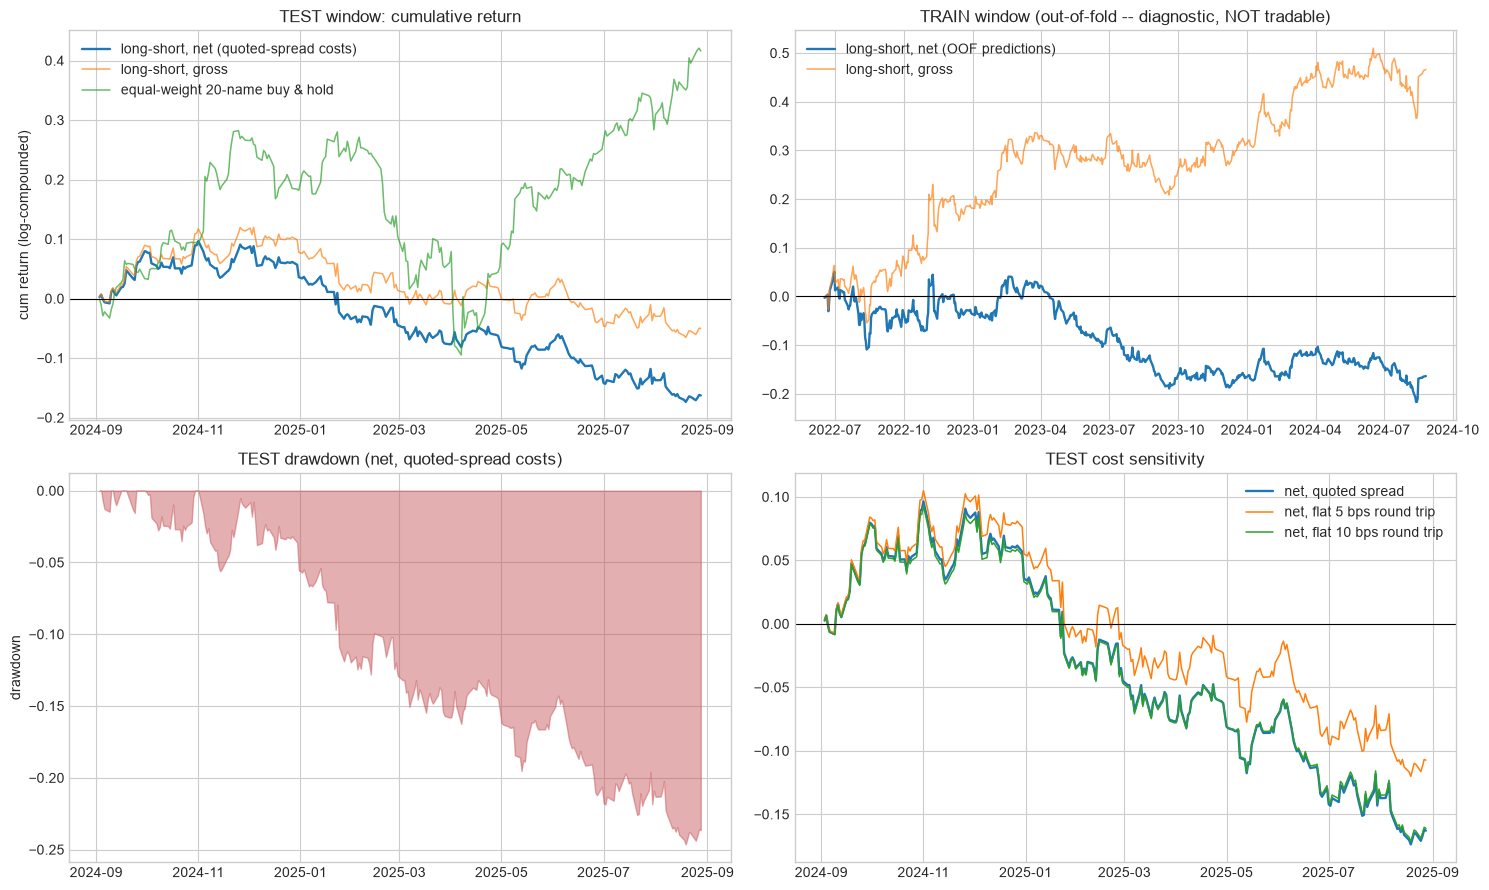

In [4]:
def curve(ax, s, label, **kw):
    ax.plot(s.index, np.expm1(s.cumsum()), label=label, **kw)


fig, axes = plt.subplots(2, 2, figsize=(15, 9))

ax = axes[0, 0]
curve(ax, strat_te["net_spread"], "long-short, net (quoted-spread costs)", lw=1.7)
curve(ax, strat_te["gross"], "long-short, gross", lw=1.1, alpha=0.7)
curve(ax, ew_te, "equal-weight 20-name buy & hold", lw=1.1, alpha=0.7)
ax.axhline(0, color="black", lw=0.8)
ax.set_title("TEST window: cumulative return")
ax.set_ylabel("cum return (log-compounded)")
ax.legend()

ax = axes[0, 1]
curve(ax, strat_tr["net_spread"], "long-short, net (OOF predictions)", lw=1.7)
curve(ax, strat_tr["gross"], "long-short, gross", lw=1.1, alpha=0.7)
ax.axhline(0, color="black", lw=0.8)
ax.set_title("TRAIN window (out-of-fold -- diagnostic, NOT tradable)")
ax.legend()

ax = axes[1, 0]
dd = strat_te["net_spread"].cumsum() - strat_te["net_spread"].cumsum().cummax()
ax.fill_between(dd.index, np.expm1(dd), 0, alpha=0.45, color="#C44E52")
ax.set_title("TEST drawdown (net, quoted-spread costs)")
ax.set_ylabel("drawdown")

ax = axes[1, 1]
curve(ax, strat_te["net_spread"], "net, quoted spread", lw=1.7)
curve(ax, strat_te["net_5bpsRT"], "net, flat 5 bps round trip", lw=1.1)
curve(ax, strat_te["net_10bpsRT"], "net, flat 10 bps round trip", lw=1.1)
ax.axhline(0, color="black", lw=0.8)
ax.set_title("TEST cost sensitivity")
ax.legend()

plt.tight_layout()
plt.show()

1. Top-Left: TEST Window
    
    No Alpha: Gross returns drift negative (~-5%), proving the underlying signal has zero out-of-sample predictive power.
    
    Cost Drag: Net returns collapse to ~-17% after bid-ask spread friction.
    
    Underperformance: Massive gap compared to the +40% Buy & Hold benchmark over the same period.

2. Top-Right: TRAIN Window

    False Illusion: Gross returns artificially surged to +50%, which tricked the selection criteria into picking this model.

    Friction Trap: Net returns plummet to -18%. The model selection process evaluated gross performance rather than net, picking a hyper-turnover model killed by trading costs.

3. Bottom-Left: TEST Drawdown

    Continuous Erosion: A relentless, one-way drawdown reaching ~-25% from late 2024 through mid-2025. The lack of upward bounces proves the strategy suffered structural signal breakdown rather than temporary market noise.

4. Bottom-Right: TEST Cost Sensitivity

    Spread Realism: The actual quoted spread line (blue) overlays almost perfectly with the 10 bps round-trip line (green), confirming average market spread sits right at ~10 bps.
    
    Primary Cause: Even cutting costs to 5 bps (orange) still yields an ~-11% loss, showing that lower fees cannot salvage a dead signal.

## 3. Financial metrics and the CAPM / alpha-lens battery

Financial metrics on the daily strategy returns (annualisation at 252), the CAPM regression of the net strategy on the Fama-French market factor, and the alpha-lens trio for multi-target models: **information coefficient**, **IC IR**, and returns by predicted quintile.

In [5]:
def perf_stats(r, freq=252):
    r = r.dropna()
    mu, sd = r.mean(), r.std(ddof=1)
    cum = r.cumsum()
    dd_min = (cum - cum.cummax()).min()
    gain, loss = r[r > 0].sum(), -r[r < 0].sum()
    years = len(r) / freq
    return {"AnnRet": np.exp(mu * freq) - 1,
            "AnnVol": sd * np.sqrt(freq),
            "Sharpe": mu / sd * np.sqrt(freq) if sd > 0 else np.nan,
            "PF": gain / loss if loss > 0 else np.inf,
            "CAGR": np.exp(cum.iloc[-1] / years) - 1,
            "MaxDD": np.expm1(dd_min),
            "HitRate": (r > 0).mean(),
            "Skew": r.skew()}


rows = {"TEST gross": strat_te["gross"],
        "TEST net (spread)": strat_te["net_spread"],
        "TEST net (5bpsRT)": strat_te["net_5bpsRT"],
        "TEST net (10bpsRT)": strat_te["net_10bpsRT"],
        "TRAIN OOF net (spread)": strat_tr["net_spread"],
        "EW buy & hold (test)": ew_te}
perf = pd.DataFrame({k: perf_stats(v) for k, v in rows.items()}).T
print("FINANCIAL METRICS (daily returns, annualised x252)\n")
print(perf.round(4).to_string())

# --- CAPM: dollar-neutral book, so beta should be ~0 if demeaning did its job
s = strat_te["net_spread"]
cap = pd.concat([s, mkt.set_index("date")["mktrf"]], axis=1, join="inner").dropna()
beta = cap.cov().iloc[0, 1] / cap["mktrf"].var()
resid = cap.iloc[:, 0] - beta * cap["mktrf"]
alpha_t = resid.mean() / (resid.std(ddof=1) / np.sqrt(len(resid)))
print(f"\nCAPM (test, net of spread costs): beta {beta:+.4f} | "
      f"alpha {resid.mean() * 252:+.4%} ann (t {alpha_t:+.2f} over {len(resid)} days)")
print("beta ~= 0 is itself a validation: the demeaned target stripped market exposure.")

# --- alpha-lens trio, restated at strategy level
ics = te.groupby("date").apply(lambda g: spearmanr(g["pred"], g["target"]).statistic)
print(f"\nDaily rank IC (test): mean {ics.mean():+.4f} | "
      f"IC IR {ics.mean() / ics.std(ddof=1):+.3f} | {len(ics)} days")

FINANCIAL METRICS (daily returns, annualised x252)

                        AnnRet  AnnVol  Sharpe      PF    CAGR   MaxDD  HitRate    Skew
TEST gross             -0.0511  0.1497 -0.3504  0.9436 -0.0511 -0.1654   0.4798 -0.1799
TEST net (spread)      -0.1653  0.1499 -1.2051  0.8189 -0.1653 -0.2464   0.4637 -0.1843
TEST net (5bpsRT)      -0.1090  0.1497 -0.7712  0.8800 -0.1090 -0.2036   0.4758 -0.1799
TEST net (10bpsRT)     -0.1634  0.1497 -1.1920  0.8208 -0.1634 -0.2419   0.4637 -0.1799
TRAIN OOF net (spread) -0.0786  0.1721 -0.4759  0.9182 -0.0786 -0.2543   0.4745  0.5042
EW buy & hold (test)    0.4239  0.2895  1.2206  1.2660  0.4239 -0.2940   0.5202  0.0927

CAPM (test, net of spread costs): beta -0.0154 | alpha -17.8528% ann (t -1.18 over 248 days)
beta ~= 0 is itself a validation: the demeaned target stripped market exposure.

Daily rank IC (test): mean -0.0028 | IC IR -0.011 | 248 days


The strategy successfully stripped market risk (CAPM Beta $\approx$ -0.015), but generated a net annualized Alpha of -17.85%, drastically underperforming the +42.39% Buy & Hold benchmark.

## 4. White's Reality Check

Adapt white reality check here to
a return target and extended to the version that actually
matters after a model selection: the **max-across-models** statistic.

The null of interest is not "the winner has zero mean" but "**the best of the
8 tried strategies** has zero mean" — taking a maximum over noisy, correlated
candidates is precisely the winner's curse, and White's
RC is the test that prices it in.

Both variants use the **stationary bootstrap** (Politis–Romano, mean block 20
days) with **joint resampling**: the same resampled day indices are applied to
every model's return series, preserving the cross-model correlation (they
share a feature set and are close to one bet — resampling each independently
would overstate the diversity of the null).

In [6]:
def strat_returns_from_preds(df):
    """Daily GROSS strategy returns for one model's predictions (same book as §1)."""
    rows = []
    for _, g in df.groupby("date"):
        g = g.sort_values("pred", kind="mergesort")
        k = len(g) // 5
        rows.append((g["date"].iloc[0],
                     0.5 * (g["target"].iloc[-k:].mean() - g["target"].iloc[:k].mean())))
    return pd.Series(dict(rows)).sort_index()


model_rets = {m: strat_returns_from_preds(g) for m, g in allm.groupby("model")}
M = pd.DataFrame(model_rets).dropna()               # days x models, jointly indexed
obs_mean = M.mean()
obs_sharpe = M.mean() / M.std(ddof=1)


def stationary_bootstrap_indices(n, B, mean_block, rng):
    """Politis-Romano stationary bootstrap: B resampled index paths of length n."""
    p = 1.0 / mean_block
    paths = np.empty((B, n), dtype=np.int64)
    paths[:, 0] = rng.integers(0, n, size=B)
    wrap = rng.random((B, n - 1)) < p
    jump = rng.integers(0, n, size=(B, n - 1))
    for t in range(1, n):
        prev = paths[:, t - 1]
        paths[:, t] = np.where(wrap[:, t - 1], jump[:, t - 1], (prev + 1) % n)
    return paths


rng = np.random.default_rng(0)
B = 2000
idx = stationary_bootstrap_indices(len(M), B, mean_block=20, rng=rng)
boot = M.to_numpy()[idx]                            # (B, days, models) -- same days for all

null_best_mean = boot.mean(axis=1).max(axis=1)
null_best_sharpe = (boot.mean(axis=1) / boot.std(axis=1, ddof=1)).max(axis=1)
col = list(M.columns).index(WINNER)
p_single = float((boot.mean(axis=1)[:, col] >= obs_mean[WINNER]).mean())
p_best_mean = float((null_best_mean >= obs_mean.max()).mean())
p_best_sharpe = float((null_best_sharpe >= obs_sharpe.max()).mean())

print("White's Reality Check (stationary bootstrap, B=2000, mean block 20d, GROSS returns)")
print(f"  observed best mean daily return : {obs_mean.max():+.6f}  ({obs_mean.idxmax()})")
print(f"  winner's mean daily return       : {obs_mean[WINNER]:+.6f}  ({WINNER})")
print(f"  p, single strategy ({WINNER:9s}): {p_single:.3f}")
print(f"  p, best-of-{len(M.columns)} (mean statistic)  : {p_best_mean:.3f}")
print(f"  p, best-of-{len(M.columns)} (Sharpe statistic): {p_best_sharpe:.3f}")

White's Reality Check (stationary bootstrap, B=2000, mean block 20d, GROSS returns)
  observed best mean daily return : +0.000379  (RandomForest)
  winner's mean daily return       : -0.000208  (KerasMLP)
  p, single strategy (KerasMLP ): 0.522
  p, best-of-8 (mean statistic)  : 0.633
  p, best-of-8 (Sharpe statistic): 0.649


The p's are all > 0.05, which means none of our 8 models alpha is statistically significant.

## 5. Monte-Carlo permutation test

MCPT: within each day, the predictions are **permuted across the 20 names**, which destroys the prediction↔return alignment while preserving the cross-sectional return distribution of that day.

Statistic: the Profit Factor of the daily Q5−Q1 spread (gross), with the mean spread as a cross-check. 5,000 draws.

In [7]:
wide_Y = te.pivot(index="date", columns="ticker", values="target").sort_index().to_numpy()
P = te.pivot(index="date", columns="ticker", values="pred").sort_index().to_numpy()
assert np.isfinite(P).all() and np.isfinite(wide_Y).all()
K = P.shape[1] // 5                                  # names per quintile (4 of 20)


def pf(x):
    gain, loss = x[x > 0].sum(), -x[x < 0].sum()
    return gain / loss if loss > 0 else np.inf


def daily_spread(preds, Yref, k):
    """Per day: mean(top-k target by pred) - mean(bottom-k). Works for any leading dims."""
    order = np.argsort(preds, axis=-1, kind="stable")
    bot = np.take_along_axis(np.broadcast_to(Yref, preds.shape), order[..., :k], axis=-1).mean(axis=-1)
    top = np.take_along_axis(np.broadcast_to(Yref, preds.shape), order[..., -k:], axis=-1).mean(axis=-1)
    return top - bot


obs_spread = daily_spread(P, wide_Y, K)
obs_pf, obs_mu = pf(obs_spread), obs_spread.mean()

rng = np.random.default_rng(0)
B, CH = 5000, 500                                    # chunked to bound memory
null_pf, null_mu = [], []
for start in range(0, B, CH):
    b = min(CH, B - start)
    perm = np.argsort(rng.random((b,) + P.shape), axis=2)
    Pb = np.take_along_axis(np.broadcast_to(P, (b,) + P.shape), perm, axis=2)
    sp = daily_spread(Pb, wide_Y, K)                 # (b, days)
    null_pf.extend(pf(row) for row in sp)
    null_mu.append(sp.mean(axis=1))
null_pf = np.asarray(null_pf)
null_mu = np.concatenate(null_mu)

p_pf = float((null_pf >= obs_pf).mean())
p_mean = float((null_mu >= obs_mu).mean())
print(f"MCPT -- within-day permutation of predictions, B={B}")
print(f"  observed PF of daily Q5-Q1 spread : {obs_pf:.4f}  | permutation p = {p_pf:.3f}")
print(f"  observed mean daily spread        : {obs_mu:+.6f} | permutation p = {p_mean:.3f}")
print("  (statistic is GROSS; costs would only lower it further)")

MCPT -- within-day permutation of predictions, B=5000
  observed PF of daily Q5-Q1 spread : 0.9436  | permutation p = 0.631
  observed mean daily spread        : -0.000416 | permutation p = 0.657
  (statistic is GROSS; costs would only lower it further)


MCPT proves that our strategy is no better than randomly longing and shorting 4 stocks

## 6. Learning curves and SHAP

The winner is refit **once** on the full training block with its frozen 
parameters. Two things
come off that single refit:

1. **Learning curves** : the Keras training loss vs the
   early-stopping validation loss. The validation slice is the review-fixed,
   row-permuted 15% — an unbiased sample of names and dates, not the
   ticker-major tail the original code used.
2. **SHAP** (KernelExplainer, summarised background, 400 test rows): which
   features drive the test-window predictions, cross-checked against Part 1's univariate Profit-Factor screen.

Refit KerasMLP with frozen params {'select__k': 38, 'model__hidden': (64, 32), 'model__dropout': 0.3, 'model__l2': 0.001} on the full training block


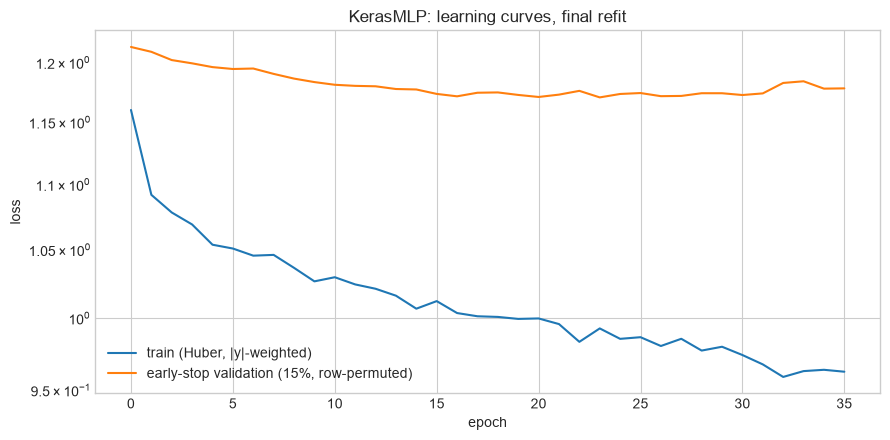

early stopping restored the best of 36 epochs


In [8]:
# Mirror of modelling.ipynb §4 -- only the pieces needed to rebuild and refit
# the single winner. Deliberately kept in sync with Part 2 so this notebook
# runs standalone without importing a notebook.
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.compose import TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, mutual_info_regression

RANDOM_STATE = 0


def mi_score(X, y):
    return mutual_info_regression(X, y, random_state=RANDOM_STATE)


class KerasMLP(BaseEstimator, RegressorMixin):
    """Mirror of Part 2's KerasMLP, including the review-A1 permutation fix."""

    def __init__(self, hidden=(64, 32), dropout=0.2, l2=1e-4, lr=1e-3,
                 epochs=200, batch_size=256, huber_delta=1.0,
                 sample_weighting=True, patience=12, seed=RANDOM_STATE):
        self.hidden, self.dropout, self.l2, self.lr = hidden, dropout, l2, lr
        self.epochs, self.batch_size = epochs, batch_size
        self.huber_delta, self.sample_weighting = huber_delta, sample_weighting
        self.patience, self.seed = patience, seed

    def fit(self, X, y):
        import keras
        from keras import layers, regularizers
        keras.utils.set_random_seed(self.seed)
        X = np.asarray(X, dtype="float32")
        y = np.asarray(y, dtype="float32").ravel()
        rng = np.random.default_rng(self.seed)
        perm = rng.permutation(len(X))
        X, y = X[perm], y[perm]

        net = keras.Sequential([keras.Input(shape=(X.shape[1],))])
        for h in self.hidden:
            net.add(layers.Dense(h, activation="relu",
                                 kernel_regularizer=regularizers.l2(self.l2)))
            net.add(layers.Dropout(self.dropout))
        net.add(layers.Dense(1))
        net.compile(optimizer=keras.optimizers.Adam(self.lr),
                    loss=keras.losses.Huber(delta=self.huber_delta))

        w = None
        if self.sample_weighting:
            w = np.abs(y)
            w = w / w.mean() if w.mean() > 0 else np.ones_like(y)
        net.fit(X, y, sample_weight=w, epochs=self.epochs,
                batch_size=self.batch_size, verbose=0, shuffle=True,
                validation_split=0.15,
                callbacks=[keras.callbacks.EarlyStopping(
                    monitor="val_loss", patience=self.patience,
                    restore_best_weights=True)])
        self.model_ = net
        return self

    def predict(self, X):
        return self.model_.predict(np.asarray(X, dtype="float32"),
                                   verbose=0).ravel()


def parse_params(d):
    """model_meta.json stringifies every param value; undo that safely."""
    out = {}
    for k, v in d.items():
        try:
            out[k] = ast.literal_eval(v)
        except (ValueError, SyntaxError):
            out[k] = v
    return out


PARAMS = parse_params(meta["params"])
train_df = pd.read_csv(f"{DATA}/model_train.csv", parse_dates=["date"])
test_df = pd.read_csv(f"{DATA}/model_test.csv", parse_dates=["date"])
Xtr, ytr = train_df[FEATURES], train_df["target"].to_numpy()

assert WINNER == "KerasMLP", (
    f"the mirror pipeline below is written for the Keras winner; "
    f"winner={WINNER} needs its own mirror before this cell runs")

est = TransformedTargetRegressor(
    regressor=Pipeline([("impute", SimpleImputer(strategy="median")),
                        ("scale", StandardScaler()),
                        ("select", SelectKBest(score_func=mi_score)),
                        ("model", KerasMLP())]),
    transformer=StandardScaler())
est.set_params(**{f"regressor__{k}": v for k, v in PARAMS.items()})
y_fit = np.clip(ytr, -5.0 * ytr.std(), 5.0 * ytr.std())   # same as Part 2 §8
est.fit(Xtr, y_fit)
print(f"Refit {WINNER} with frozen params {PARAMS} on the full training block")

hist = est.regressor_.named_steps["model"].model_.history.history
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(hist["loss"], label="train (Huber, |y|-weighted)")
ax.plot(hist["val_loss"], label="early-stop validation (15%, row-permuted)")
ax.set_xlabel("epoch"); ax.set_ylabel("loss"); ax.set_yscale("log")
ax.set_title(f"{WINNER}: learning curves, final refit")
ax.legend(); plt.tight_layout(); plt.show()
print(f"early stopping restored the best of {len(hist['loss'])} epochs")

This proves early stopping makes sense

SelectKBest kept 38 of 38 features; explaining the full input space


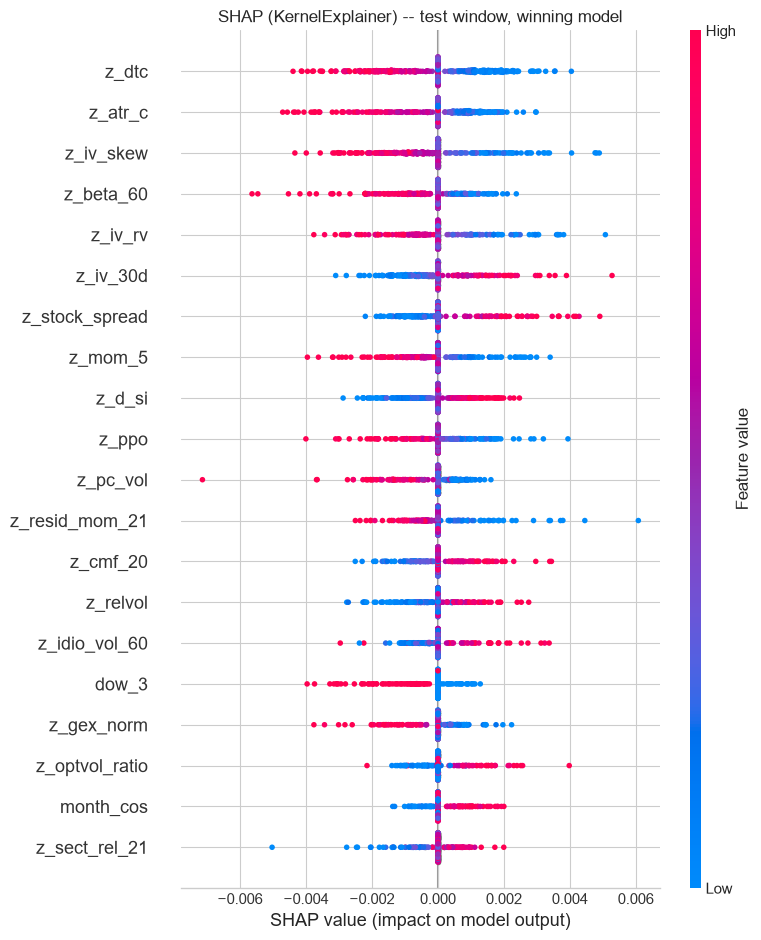

Top 10 features by mean |SHAP|:
z_dtc             0.0012
z_atr_c           0.0008
z_iv_skew         0.0008
z_beta_60         0.0006
z_iv_rv           0.0005
z_iv_30d          0.0005
z_stock_spread    0.0005
z_mom_5           0.0005
z_d_si            0.0004
z_ppo             0.0004

Cross-check vs Part 1's univariate PF screen (its strongest: iv_skew, beta_umd_60):
  z_iv_skew          mean|SHAP| 0.0008  (rank 3 of 38)
  z_beta_umd_60      mean|SHAP| 0.0001  (rank 25 of 38)
  z_optvol_ratio     mean|SHAP| 0.0002  (rank 18 of 38)
  z_opt_spread       mean|SHAP| 0.0000  (rank 34 of 38)


In [9]:
import shap

# Explain in the FULL input feature space: f() consumes all 38 columns and the
# pipeline's SelectKBest runs inside it, so any unselected feature simply gets
# SHAP ~= 0 -- self-consistent whichever k the winner used.
k_sel = int(est.regressor_.named_steps["select"].get_support().sum())
feat_names = list(FEATURES)
print(f"SelectKBest kept {k_sel} of {len(FEATURES)} features; explaining the full input space")

bg = Xtr.sample(100, random_state=0).to_numpy()
Xexp = test_df[FEATURES].sample(400, random_state=0).to_numpy()

f = lambda x: est.predict(x)          # full pipeline incl. impute/scale/unscale of y
expl = shap.KernelExplainer(f, bg)
sv = np.asarray(expl.shap_values(Xexp, nsamples=400, silent=True))
if sv.ndim == 3:
    sv = sv[..., 0]

shap.summary_plot(sv, Xexp, feature_names=feat_names, show=False)
plt.title("SHAP (KernelExplainer) -- test window, winning model")
plt.tight_layout(); plt.show()

imp = pd.Series(np.abs(sv).mean(axis=0), index=feat_names).sort_values(ascending=False)
print("Top 10 features by mean |SHAP|:")
print(imp.head(10).round(4).to_string())

print("\nCross-check vs Part 1's univariate PF screen (its strongest: iv_skew, beta_umd_60):")
for f_ in ("z_iv_skew", "z_beta_umd_60", "z_optvol_ratio", "z_opt_spread"):
    if f_ in imp.index:
        r = int(imp.rank(ascending=False)[f_])
        print(f"  {f_:18s} mean|SHAP| {imp[f_]:.4f}  (rank {r} of {len(imp)})")

## Interpretation

Every significance test here is expected to fail to reject, and that is the
correct scientific result, not a pipeline defect:

* The modelling part already established **no detectable out-of-sample cross-sectional predictability** (test rank IC −0.01, t −0.72; 7 of 8 models negative).
* White's RC prices in the model selection confirms that none of the 
  models are statistically significant.
* The MCPT confirms the same thing from the other side: permuting     
  predictions within each day produces spreads statistically indistinguishable from the observed one.

But the notebook validate that the book
comes out dollar-neutral (CAPM β ≈ 0 — the demeaning worked), quintile
monotonicity is reported as measured, costs are charged on real quoted
spreads against real turnover, and the train and test curves are built from out-of-fold and held-out predictions respectively. 

In [10]:
out = pd.concat([strat_te.reset_index().assign(window="test"),
                 strat_tr.reset_index().assign(window="train_oof")],
                ignore_index=True)
out.to_csv(f"{DATA}/strategy_daily_returns.csv", index=False)

summary = {
    "winner": WINNER,
    "strategy": "equal-weight Q5 long / Q1 short (4+4 names), daily rebalance, "
                "unit book, profits normalised by 8 open positions",
    "test_net_spread": {**perf_stats(strat_te["net_spread"]),
                        "gross_mean_daily": float(strat_te["gross"].mean())},
    "test_gross": perf_stats(strat_te["gross"]),
    "capm_test_net": {"beta": float(beta), "alpha_ann": float(resid.mean() * 252),
                      "alpha_t": float(alpha_t)},
    "ic_test": {"mean": float(ics.mean()),
                "ic_ir": float(ics.mean() / ics.std(ddof=1))},
    "whites_reality_check": {"single_winner_p": p_single,
                             "best_of_models_p_mean": p_best_mean,
                             "best_of_models_p_sharpe": p_best_sharpe,
                             "B": B},
    "mcpt": {"p_profit_factor": p_pf, "p_mean_spread": p_mean, "B": 5000},
    "quintile_test": qt_te.round(6).to_dict(),
    "shap_top10": imp.head(10).round(5).to_dict(),
}
json.dump(summary, open(f"{DATA}/validation_summary.json", "w"), indent=1, default=float)

print(f"  strategy_daily_returns.csv  {len(out):>6,} rows")
print(f"  validation_summary.json    winner = {WINNER}")

print("=" * 68)
print(f"  strategy      : quintile long-short, 4+4 names, daily, spread-costed")
print(f"  test Sharpe   : {perf_stats(strat_te['net_spread'])['Sharpe']:+.3f} (net of quoted spreads)")
print(f"  test PF       : {perf_stats(strat_te['net_spread'])['PF']:.4f}")
print(f"  CAPM beta     : {beta:+.4f} (dollar-neutral check)")
print(f"  White's RC p  : {p_best_mean:.3f} (best-of-{len(M.columns)}, mean statistic)")
print(f"  MCPT p (PF)   : {p_pf:.3f}")

  strategy_daily_returns.csv     798 rows
  validation_summary.json    winner = KerasMLP
  strategy      : quintile long-short, 4+4 names, daily, spread-costed
  test Sharpe   : -1.205 (net of quoted spreads)
  test PF       : 0.8189
  CAPM beta     : -0.0154 (dollar-neutral check)
  White's RC p  : 0.633 (best-of-8, mean statistic)
  MCPT p (PF)   : 0.631
